# 11 A picture of the vectors (t-SNE)
A picture vector is a list of 512 numbers, and nobody can look at that. **t-SNE** squeezes each list into just two numbers, so that every product becomes a dot on a flat picture (van der Maaten and Hinton, 2008). Products with similar vectors land close together. It is only for looking: it does not change any result, and the search does not use it. Here I use it to check two things: do the picture vectors put similar products together, and does the picture change when the vectors are shortened with PCA (notebook 10)? Nothing here uses the 20 locked final products.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(root)  # the project reads data/archive.zip relative to the project folder
sys.path.insert(0, str(root / "experiments"))
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

from ann_data import load_spaces  # noqa: E402
from sklearn.decomposition import PCA  # noqa: E402
from sklearn.manifold import TSNE  # noqa: E402

spaces, _, products = load_spaces()
space = spaces["picture"]
print("picture vectors:", space.matrix.shape)

picture vectors: (29366, 512)


## 1. How I did it
- **The products.** 3,000 random products (seed 2020), taken from the 29,366 products that have a picture vector.
- **Three versions of the same products.** The full 512 numbers; the vectors cut to 128 numbers with PCA; and cut to 64 numbers with PCA. PCA is trained on all the picture vectors.
- **t-SNE.** Each version is squeezed into two numbers (perplexity 30, seed 2020). The three pictures are separate runs, so the shapes can be turned or flipped, and only the groups matter.
- **Colours.** The eight biggest categories among the 3,000 products have their own colour. All other products are grey.

In [2]:
rng = np.random.default_rng(2020)
pick = rng.choice(len(space.rows), 3000, replace=False)
categories = pd.Series([products[int(space.rows[i])].category or "no category" for i in pick])
top = categories.value_counts().head(8).index.tolist()
print(categories.value_counts().head(8).to_string())

panels = {"full vectors (512 numbers)": space.matrix[pick]}
for dims in (128, 64):
    reducer = PCA(n_components=dims, random_state=2020).fit(space.matrix)
    panels[f"PCA, {dims} numbers"] = reducer.transform(space.matrix[pick])

MensT_Shirts             366
WomensKurtasKurtis       363
MensCapsHats             183
WomensSarees             167
GirlsDressesJumpsuits    114
BoysT_Shirts             111
MensFormalShirts         104
MensCasualShirts          88


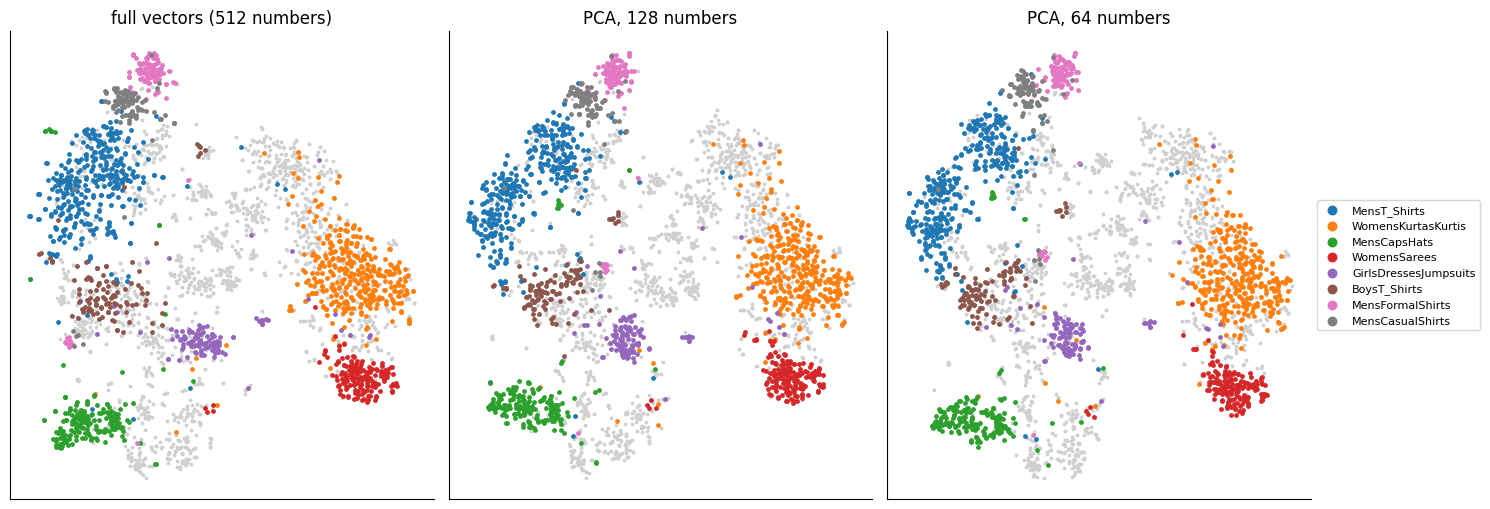

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
for ax, (title, vectors) in zip(axes, panels.items()):
    points = TSNE(n_components=2, perplexity=30, init="pca", random_state=2020).fit_transform(vectors)
    other = ~categories.isin(top)
    ax.scatter(points[other, 0], points[other, 1], s=3, color="#d0d0d0")
    for name in top:
        m = (categories == name).to_numpy()
        ax.scatter(points[m, 0], points[m, 1], s=6, label=name)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title)
axes[2].legend(markerscale=2.5, fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
fig.savefig(root / "evaluation" / "tsne_picture_vectors.png", dpi=110, bbox_inches="tight")
plt.show()

### What this shows
Products of the same category sit together: men's T-shirts, kurtas, sarees and caps and hats each form their own area, and the shirts form smaller groups. The grey products, which are in the smaller categories, are spread in between. The three pictures look almost the same, so the groups stay in place when the vectors are cut to 128 or even 64 numbers.

References: van der Maaten and Hinton, [Visualizing data using t-SNE](https://www.jmlr.org/papers/v9/vandermaaten08a.html) (2008) (t-SNE); Jolliffe and Cadima, [Principal component analysis: a review and recent developments](https://doi.org/10.1098/rsta.2015.0202) (2016) (PCA).

## 2. Conclusion

**What I wanted to know:** do the picture vectors put similar products close together, and does PCA keep that?

**What I did.** I took 3,000 random products and squeezed their picture vectors into two numbers with t-SNE, three times: with the full 512 numbers and after PCA to 128 and to 64 numbers. I coloured the eight biggest categories.

**What I found**

- Products of the same category sit together: men's T-shirts, kurtas, sarees and caps and hats each form their own area. The picture vectors capture the kind of product, which is why a search over them works.
- The three pictures look almost the same. The big groups stay together in the same places, even with 64 numbers. So PCA keeps the overall shape.
- What PCA loses is the fine detail. Inside one big group there are many similar products, and which ones are the closest 10 changes a little when the vectors are cut. That is probably why the recall dropped in notebook 10.

**What I can't say yet**

- The picture is a rough view: distances in it are not exact, and it shows 3,000 products out of about 29,500.
- It does not replace the recall numbers. Those come from notebooks 09 and 10.

**What I do next.** I will make the service stronger (checks on the input and proper error codes), and then add caching, Kubernetes and the weights page.